In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate,
                               false_positive_rate, demographic_parity_difference,
                               demographic_parity_ratio, equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer

RS = 42

In [9]:
df = pd.read_csv("adult.csv", skipinitialspace=True)
df.columns = [c.strip() for c in df.columns]
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()
df = df.replace("?", np.nan).dropna().reset_index(drop=True)
print("Rows after cleaning:", len(df))
df.head()

Rows after cleaning: 30162


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
1,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
2,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
3,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
4,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K


In [10]:
y = df["income"].astype(str).str.replace(".", "", regex=False).eq(">50K").astype(int)
sex = df["sex"]
X = df.drop(columns=["income", "sex"])        # sex NOT used as a feature

X_tr, X_te, y_tr, y_te, s_tr, s_te = train_test_split(
    X, y, sex, test_size=0.30, stratify=y, random_state=RS)

cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
model.fit(X_tr, y_tr)
print("Trained without 'sex'. Train:", len(X_tr), "Test:", len(X_te))

Trained without 'sex'. Train: 21113 Test: 9049


In [11]:
def audit(y_true, y_pred, sens):
    mf = MetricFrame(metrics={"accuracy": accuracy_score, "selection_rate": selection_rate,
                              "tpr": true_positive_rate, "fpr": false_positive_rate},
                     y_true=y_true, y_pred=y_pred, sensitive_features=sens)
    r = {"acc": accuracy_score(y_true, y_pred),
         "sel_m": mf.by_group.loc["Male", "selection_rate"],
         "sel_f": mf.by_group.loc["Female", "selection_rate"],
         "dp_diff": demographic_parity_difference(y_true, y_pred, sensitive_features=sens),
         "dp_ratio": demographic_parity_ratio(y_true, y_pred, sensitive_features=sens),
         "eo_diff": equalized_odds_difference(y_true, y_pred, sensitive_features=sens)}
    return mf, r

In [12]:
mf_b, r_b = audit(y_te, model.predict(X_te), s_te)
print(f"Baseline model : Logistic Regression   Accuracy : {r_b['acc']:.2f}\n")
print(mf_b.by_group.round(2))

Baseline model : Logistic Regression   Accuracy : 0.85

        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.92            0.09  0.53  0.03
Male        0.82            0.26  0.62  0.09


In [13]:
flag = "BIAS" if r_b["dp_ratio"] < 0.80 else "OK"
print(f"Demographic parity difference : {r_b['dp_diff']:.2f}")
print(f"Demographic parity ratio (DI) : {r_b['dp_ratio']:.2f}  -> {flag}")
print(f"Equalized odds difference     : {r_b['eo_diff']:.2f}")

Demographic parity difference : 0.17
Demographic parity ratio (DI) : 0.34  -> BIAS
Equalized odds difference     : 0.08


In [14]:
def run_to(constraint):
    to = ThresholdOptimizer(estimator=model, constraints=constraint,
                            objective="accuracy_score", prefit=True,
                            predict_method="predict_proba")
    to.fit(X_tr, y_tr, sensitive_features=s_tr)
    pred = to.predict(X_te, sensitive_features=s_te, random_state=RS)
    return audit(y_te, pred, s_te)

mf_dp, r_dp = run_to("demographic_parity")
print(f"TO: demographic_parity   Accuracy : {r_dp['acc']:.2f}\n")
print(mf_dp.by_group.round(2))
print(f"\nDP difference : {r_dp['dp_diff']:.2f}")
print(f"DP ratio      : {r_dp['dp_ratio']:.2f}")
print(f"EO difference : {r_dp['eo_diff']:.2f}")

TO: demographic_parity   Accuracy : 0.83

        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.89            0.17  0.77  0.10
Male        0.80            0.18  0.47  0.04

DP difference : 0.00
DP ratio      : 0.99
EO difference : 0.30


In [15]:
mf_eo, r_eo = run_to("equalized_odds")
print(f"TO: equalized_odds   Accuracy : {r_eo['acc']:.2f}\n")
print(mf_eo.by_group.round(2))
print(f"\nDP difference : {r_eo['dp_diff']:.2f}")
print(f"DP ratio      : {r_eo['dp_ratio']:.2f}")
print(f"EO difference : {r_eo['eo_diff']:.2f}")

TO: equalized_odds   Accuracy : 0.83

        accuracy  selection_rate   tpr   fpr
sex                                         
Female      0.87            0.14  0.55  0.09
Male        0.81            0.23  0.57  0.07

DP difference : 0.09
DP ratio      : 0.61
EO difference : 0.02


In [16]:
rows = [("Baseline", r_b), ("TO: demographic_par.", r_dp), ("TO: equalized_odds", r_eo)]
comp = pd.DataFrame([{"Model": n, "ACC": r["acc"], "SEL_M": r["sel_m"], "SEL_F": r["sel_f"],
                      "DP_DIFF": r["dp_diff"], "EO_DIFF": r["eo_diff"]}
                     for n, r in rows]).round(2)
print(comp.to_string(index=False))
comp.to_csv("comparison_table.csv", index=False)
print("\nAccuracy lost (demographic parity):", round(r_b["acc"] - r_dp["acc"], 3))
print("Accuracy lost (equalized odds)    :", round(r_b["acc"] - r_eo["acc"], 3))

               Model  ACC  SEL_M  SEL_F  DP_DIFF  EO_DIFF
            Baseline 0.85   0.26   0.09     0.17     0.08
TO: demographic_par. 0.83   0.18   0.17     0.00     0.30
  TO: equalized_odds 0.83   0.23   0.14     0.09     0.02

Accuracy lost (demographic parity): 0.019
Accuracy lost (equalized odds)    : 0.016


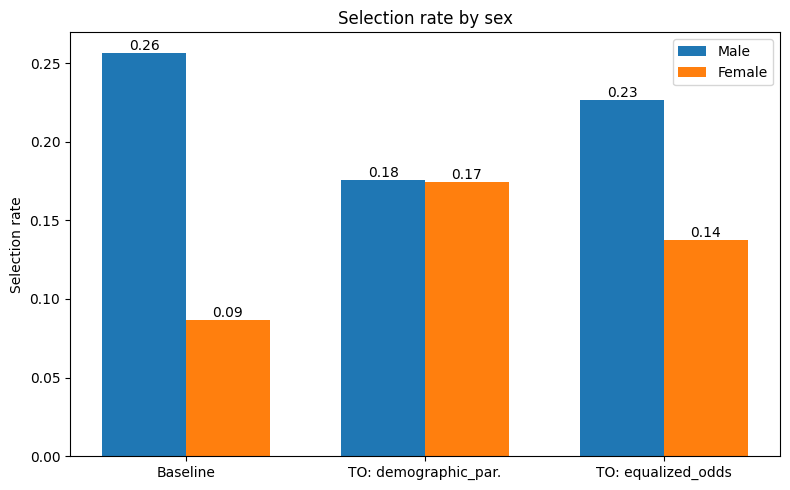

Plot saved : selection_rate_by_sex.png
No single model satisfies both fairness definitions.


In [17]:
labels = [n for n, _ in rows]
male = [r["sel_m"] for _, r in rows]
fem = [r["sel_f"] for _, r in rows]
x = np.arange(len(labels)); w = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, male, w, label="Male")
b2 = ax.bar(x + w/2, fem, w, label="Female")
ax.bar_label(b1, fmt="%.2f"); ax.bar_label(b2, fmt="%.2f")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Selection rate"); ax.set_title("Selection rate by sex"); ax.legend()
plt.tight_layout()
plt.savefig("selection_rate_by_sex.png", dpi=150)
plt.show()
print("Plot saved : selection_rate_by_sex.png")
print("No single model satisfies both fairness definitions.")